In [1]:
import pandas as pd 
from matplotlib import pyplot as plt 
import seaborn as sns
import numpy as np 

df=pd.read_excel('income.xlsx')
df.head()


,Name,Age,Income (Thousands $)
0,Rob,29,45
1,Andrea,50,80
2,Mohan,35,52
3,Michael,32,41
4,Kory,36,87


<Axes: xlabel='Age', ylabel='Income (Thousands $)'>

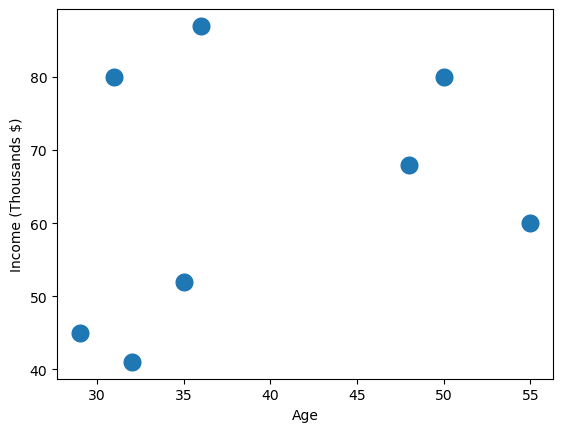

In [2]:
sns.scatterplot(df,x='Age',y='Income (Thousands $)',s=200)

In [4]:
from sklearn.cluster import AgglomerativeClustering

hc=AgglomerativeClustering(n_clusters=3,linkage='average')

hc.fit(df.drop('Name',axis=1))
hc.labels_

array([1, 0, 1, 1, 2, 0, 2, 0])

In [5]:
df['Clusters']=hc.labels_
df.head()

,Name,Age,Income (Thousands $),Clusters
0,Rob,29,45,1
1,Andrea,50,80,0
2,Mohan,35,52,1
3,Michael,32,41,1
4,Kory,36,87,2


<Axes: xlabel='Age', ylabel='Income (Thousands $)'>

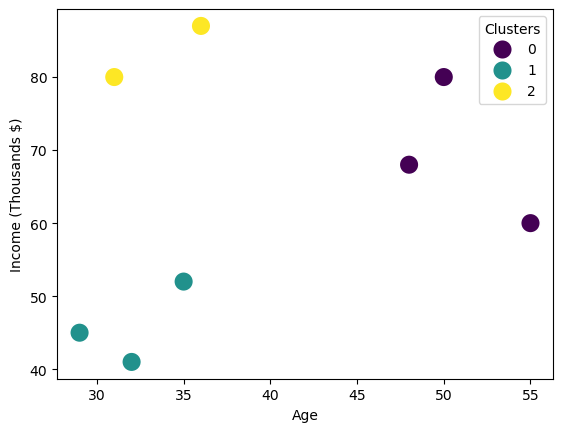

In [7]:
sns.scatterplot(df,x='Age',y='Income (Thousands $)',s=200,hue='Clusters',palette='viridis')

In [8]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [9]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

X=df[['Age','Income (Thousands $)']]
Z=linkage(X,method='average')
Z #it shows the merge opertion of clusters



array([[ 0.        ,  3.        ,  5.        ,  2.        ],
       [ 4.        ,  6.        ,  8.60232527,  2.        ],
       [ 2.        ,  8.        , 10.31064935,  3.        ],
       [ 5.        ,  7.        , 10.63014581,  2.        ],
       [ 1.        , 11.        , 16.39052659,  3.        ],
       [ 9.        , 12.        , 23.69824661,  5.        ],
       [10.        , 13.        , 33.65863823,  8.        ]])

array([[dp1, dp2, dist,]])

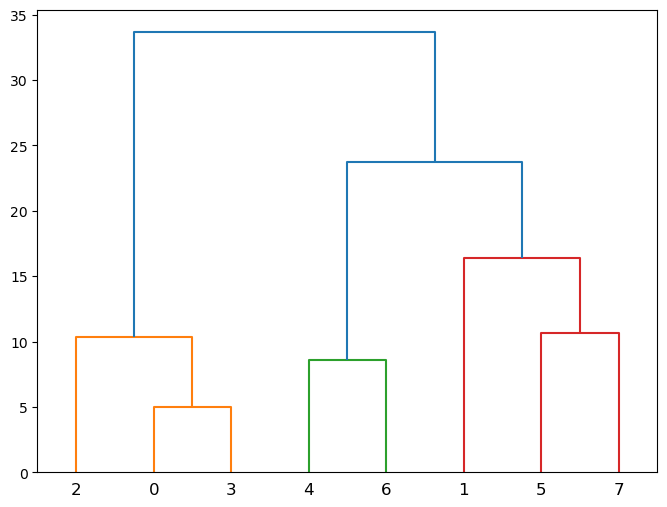

In [12]:
#Plotting dendogram 
plt.figure(figsize=(8, 6))

dendrogram(Z)
plt.show()

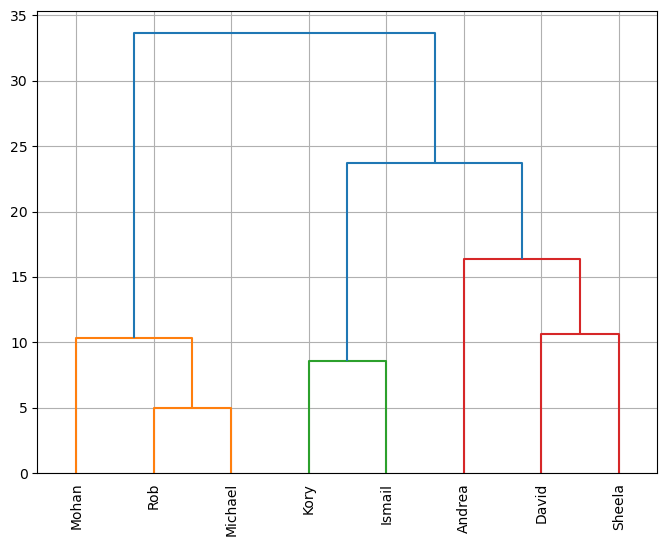

In [18]:
plt.figure(figsize=(8, 6))

dendrogram(Z,labels=df['Name'].values,leaf_rotation=90,leaf_font_size=10)
plt.grid()
plt.show()

In [22]:
fcluster(Z,t=3,criterion='maxclust')

array([1, 3, 1, 1, 2, 3, 2, 3], dtype=int32)